# Building and Training a Feedforward Neural Network for Language Modeling — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/08-foundational-nlp-models/notebooks/building-and-training-a-feedforward-neural-network-for-language-modeling.ipynb) · [Course notes](../../../courses/08-foundational-nlp-models/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Building and Training a Feedforward Neural Network for Language Modeling**

Estimated time needed: **60** minutes

This project explores the use of Feedforward Neural Networks (FNNs) in language modeling. The primary objective is to build a neural network that learns word relationships and generates meaningful text sequences. The implementation is done using PyTorch, covering key aspects of Natural Language Processing (NLP), such as:
* Tokenization & Indexing: Converting text into numerical representations.
* Embedding Layers: Mapping words to dense vector representations for efficient learning.
* Context-Target Pair Generation (N-grams): Structuring training data for sequence prediction.
* Multi-Class Neural Network: Designing a model to predict the next word in a sequence.

The training process includes optimizing the model with loss functions and backpropagation techniques to improve accuracy and coherence in text generation. By the end of the project, you will have a working FNN-based language model capable of generating text sequences.
<div style="text-align:center;">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-GPXX0WSVEN/song%20%281%29.png" alt="Image Description">
</div>


# __Table of Contents__

<ol>
    <li><a href="#Objectives">Objectives</a></li>
    <li>
        <a href="#Setup">Setup</a>
        <ol>
            <li><a href="#Installing-required-libraries">Installing required libraries</a></li>
            <li><a href="#Importing-required-libraries">Importing required libraries</a></li>
            <li><a href="#Defining-helper-functions">Defining helper functions</a></li>
        </ol>
    </li>
    <li>
       <a href="#Feedforward-Neural-Networks-(FNNs)-for-language-models">Feedforward Neural Networks (FNNs) for language models</a></li>
        <ol>
            <li><a href="#Tokenization-for-FNN">Tokenization for FNN</a></li>
            <li><a href="#Indexing">Indexing</a></li>
            <li><a href="#Embedding-layers">Embedding layers</a></li>
        </ol>
</li>
    <li><a href="#Generating-context-target-pairs-(n-grams)">Generating context-target pairs (n-grams)</a></li>
    <ol>
        <li><a href="#Batch-function">Batch function</a></li>
        <li><a href="#Multi-class-neural-network">Multi-class neural network</a></li>
    </ol>
    <li><a href="#Training">Training</a></li>
    </li>
    <li><a href="#Exercises">Exercises</a></li>
    </li>
</ol>


---


# Objectives

After completing this lab, you will be able to:

 - Implement a feedforward neural network using the PyTorch framework, including embedding layers, for language modeling tasks.
 - Fine-tune the output layer of the neural network for optimal performance in text generation.
 - Apply various training strategies and fundamental Natural Language Processing (NLP) techniques, such as tokenization and sequence analysis, to improve text generation.


---


# Setup


All libraries required for this lab are listed below. The following required libraries are __not__ pre-installed in the Skills Network Labs environment. __You will need to run the code__ in the cell below to install them. However, if you run this notebook commands in a different Jupyter environment (e.g. Watson Studio or Ananconda), you may need to install additional libraries before proceeding with the lab.


For this lab, you will use the following libraries:

*   [`pandas`](https://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for managing the data.
*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for mathematical operations.
*   [`sklearn`](https://scikit-learn.org/stable/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for machine learning and machine-learning-pipeline related functions.
*   [`seaborn`](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for visualizing the data.
*   [`matplotlib`](https://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for additional plotting tools.


### Installing required libraries

<h3 style="color:red;"> Note: Installing these packages may take several minutes. Please be patient and allow the installation to finish before proceeding.</h3>

<h3 style="color:red;">After installing the libraries below please RESTART THE KERNEL and run all cells.</h3>

Note: If your environment doesn't support "!pip install", use "!mamba install"

You may comment %%capture line below if you do not want to supress the messages that appear during package installation


### Importing required libraries

_It is recommended that you import all required libraries in one place (here):_


In [2]:
import warnings
from tqdm import tqdm
warnings.simplefilter('ignore')
import time
from collections import OrderedDict
import re
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import string
import time
from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator
from nltk.tokenize import word_tokenize
from sklearn.manifold import TSNE

def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

Matplotlib is building the font cache; this may take a moment.


[nltk_data] Downloading package punkt to
[nltk_data]     <user-home>/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     <user-home>/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


---


## Feedforward Neural Networks (FNNs) for language models

FNNs, or Multi-Layer Perceptrons, serve as the foundational components for comprehending neural networks in natural language processing (NLP). In NLP tasks, FNNs process textual data by transforming it into numerical vectors known as embeddings. Subsequently, these embeddings are input to the network to predict language facets, such as the upcoming word in a sentence or the sentiment of a text.

Let's consider the following song lyrics for our analysis.


In [3]:
song = 'We are no strangers to love\nYou know the rules and so do I\nA full commitments what Im thinking of\nYou wouldnt get this from any other guy\nI just wanna tell you how Im feeling\nGotta make you understand\nNever gonna give you up\nNever gonna let you down\nNever gonna run around and desert you\nNever gonna make you cry\nNever gonna say goodbye\nNever gonna tell a lie and hurt you\nWeve known each other for so long\nYour hearts been aching but youre too shy to say it\nInside we both know whats been going on\nWe know the game and were gonna play it\nAnd if you ask me how Im feeling\nDont tell me youre too blind to see\nNever gonna give you up\nNever gonna let you down\nNever gonna run around and desert you\nNever gonna make you cry\nNever gonna say goodbye\nNever gonna tell a lie and hurt you\nNever gonna give you up\nNever gonna let you down\nNever gonna run around and desert you\nNever gonna make you cry\nNever gonna say goodbye\nNever gonna tell a lie and hurt you\nWeve known each other for so long\nYour hearts been aching but youre too shy to say it\nInside we both know whats been going on\nWe know the game and were gonna play it\nI just wanna tell you how Im feeling\nGotta make you understand\nNever gonna give you up\nNever gonna let you down\nNever gonna run around and desert you\nNever gonna make you cry\nNever gonna say goodbye\nNever gonna tell a lie and hurt you\nNever gonna give you up\nNever gonna let you down\nNever gonna run around and desert you\nNever gonna make you cry\nNever gonna say goodbye\nNever gonna tell a lie and hurt you\nNever gonna give you up\nNever gonna let you down\nNever gonna run around and desert you\nNever gonna make you cry\nNever gonna say goodbye\nNever gonna tell a lie and hurt you'

 ### Tokenization for FNN


 This PyTorch function is used to obtain a tokenizer for text.


In [4]:
tokenizer = get_tokenizer('basic_english')
tokens = tokenizer(song)

In [5]:
def preprocess_string(s):
    """
    Preprocesses a given string by performing the following steps:
    
    1. Removes all non-word characters (excluding letters and numbers).
    2. Removes all whitespace characters.
    3. Removes all numeric digits.

    Parameters:
    s (str): The input string to be cleaned.

    Returns:
    str: The processed string with only alphabetic characters, no spaces, and no digits.
    """
    s = re.sub('[^\\w\\s]', '', s)
    s = re.sub('\\s+', '', s)
    s = re.sub('\\d', '', s)
    return s

In [6]:
def preprocess(words):
    """
    Preprocesses a given text by tokenizing it, cleaning individual words, and 
    converting them to lowercase while removing empty or punctuation tokens.

    Steps:
    1. Tokenization: Splits the input text into individual word tokens.
    2. Cleaning: Applies `preprocess_string()` to remove non-word characters, 
       spaces, and digits from each token.
    3. Normalization: Converts all tokens to lowercase.
    4. Filtering: Removes empty strings and punctuation tokens.

    Parameters:
    words (str): The input text to be tokenized and preprocessed.

    Returns:
    list: A list of cleaned, lowercase tokens.
    """
    tokens = word_tokenize(words)
    tokens = [preprocess_string(w) for w in tokens]
    return [w.lower() for w in tokens if len(w) != 0 and w not in string.punctuation]
tokens = preprocess(song)

### Indexing

TorchText provides tools to tokenize text into individual words (tokens) and build a vocabulary, which maps tokens to unique integer indexes. This is a crucial step in preparing text data for  machine learning models that require numerical input.


In [7]:
def tokenizetext(song):
    """
    Tokenizes the input text (song) and builds a vocabulary from the tokens.

    Steps:
    1. Tokenization: The function splits the input text into words and applies 
       a tokenizer function to each word.
    2. Vocabulary Building: Constructs a vocabulary from the tokenized words,
       including a special "<unk>" token to handle out-of-vocabulary words.
    3. Default Indexing: Sets the default index for unknown words, ensuring 
       that any unseen tokens are mapped to "<unk>".

    Parameters:
    song (str): The input text (song lyrics) to be tokenized and processed.

    Returns:
    vocab (Vocab): A vocabulary object mapping tokens to their corresponding indices.
    """
    tokenized_song = map(tokenizer, song.split())
    vocab = build_vocab_from_iterator(tokenized_song, specials=['<unk>'])
    vocab.set_default_index(vocab['<unk>'])
    return vocab

Convert the tokens to indices by applying the function as shown here:


In [8]:
vocab = tokenizetext(song)
vocab(tokens[0:10])

[21, 58, 70, 74, 25, 69, 2, 20, 31, 72]

In [9]:
tokens[0:10]

['we', 'are', 'no', 'strangers', 'to', 'love', 'you', 'know', 'the', 'rules']



Write a text function that converts raw text into indexes.


In [10]:
text_pipeline = lambda x: vocab(tokenizer(x))
text_pipeline(song)[0:10]

[21, 58, 70, 74, 25, 69, 2, 20, 31, 72]


Find the word corresponding to an index using the```get_itos()```method. The result is a list where the index of the list corresponds to a word.


In [11]:
index_to_token = vocab.get_itos()
index_to_token[58]

'are'

## Embedding layers

An embedding layer is a crucial element in natural language processing (NLP) and neural networks designed for sequential data. It serves to convert categorical variables, like words or discrete indexes representing tokens, into continuous vectors. This transformation facilitates training and enables the network to learn meaningful relationships among words.

Let's consider a simple example involving a vocabulary of words 
- **Vocabulary**: {apple, banana, orange, pear}

Each word in your vocabulary has a unique index assigned to it: 
- **Indices**: {0, 1, 2, 3}

When using an embedding layer, you will initialize random continuous vectors for each index. For instance, the embedding vectors might look like:

- Vector for index 0 (apple): [0.2, 0.8]
- Vector for index 1 (banana): [0.6, -0.5]
- Vector for index 2 (orange): [-0.3, 0.7]
- Vector for index 3 (pear): [0.1, 0.4]
In PyTorch, you can create an embedding layer.


In [12]:
def genembedding(vocab):
    """
    Generates an embedding layer for the given vocabulary.

    The embedding layer transforms words into dense vector representations, 
    allowing the model to learn semantic relationships between words.

    Parameters:
    vocab (Vocab): The vocabulary object containing unique words and their indices.

    Returns:
    nn.Embedding: A PyTorch embedding layer with a specified embedding dimension.
    """
    embedding_dim = 20
    vocab_size = len(vocab)
    embeddings = nn.Embedding(vocab_size, embedding_dim)
    return embeddings


**Embeddings**: Obtain the embedding for the first word with index 0 or 1. Don't forget that you have to convert the input into a tensor. The embeddings are initially initialized randomly, but as the model undergoes training, words with similar meanings gradually come to cluster closer together


In [13]:
embeddings = genembedding(vocab)
for n in range(2):
    embedding = embeddings(torch.tensor(n))
    print('word', index_to_token[n])
    print('index', n)
    print('embedding', embedding)
    print('embedding shape', embedding.shape)

word <unk>
index 0
embedding tensor([ 1.9269,  1.4873,  0.9007, -2.1055,  0.6784, -1.2345, -0.0431, -1.6047,
        -0.7521,  1.6487, -0.3925, -1.4036, -0.7279, -0.5594, -0.7688,  0.7624,
         1.6423, -0.1596, -0.4974,  0.4396], grad_fn=<EmbeddingBackward0>)
embedding shape torch.Size([20])
word gonna
index 1
embedding tensor([-0.7581,  1.0783,  0.8008,  1.6806,  1.2791,  1.2964,  0.6105,  1.3347,
        -0.2316,  0.0418, -0.2516,  0.8599, -1.3847, -0.8712, -0.2234,  1.7174,
         0.3189, -0.4245,  0.3057, -0.7746], grad_fn=<EmbeddingBackward0>)
embedding shape torch.Size([20])


These vectors will serve as inputs for the next layer.


### Generating context-target pairs (n-grams)

Organize words within a variable-size context using the following approach: Each word is denoted by 'i'. 
To establish the context, simply subtract 'j'. The size of the context is determined by the value of``CONTEXT_SIZE``.


In [14]:
CONTEXT_SIZE = 2

def genngrams(tokens):
    """
    Generates n-grams from a list of tokens, where each n-gram consists of a 
    context (previous words) and a target (next word).

    The function constructs a list of tuples where:
    - The first element is a list of `CONTEXT_SIZE` previous words.
    - The second element is the target word that follows the context.

    Parameters:
    tokens (list): A list of preprocessed word tokens.

    Returns:
    list: A list of tuples representing n-grams.
          Each tuple contains (context_words, target_word).
    """
    ngrams = [([tokens[i - j - 1] for j in range(CONTEXT_SIZE)], tokens[i]) for i in range(CONTEXT_SIZE, len(tokens))]
    return ngrams

Output the first element, which results in a tuple. The initial element represents the context, and the index indicates the following word.


In [15]:
ngrams = genngrams(tokens)
context, target = ngrams[0]
print('context', context, 'target', target)
print('context index', vocab(context), 'target index', vocab([target]))

context ['are', 'we'] target no
context index [58, 21] target index [70]


In this context, there are multiple words. Aggregate the embeddings of each of these words and then adjust the input size of the subsequent layer accordingly. Then, create the next layer.


In [16]:
embedding_dim = 20
linear = nn.Linear(embedding_dim * CONTEXT_SIZE, 128)


You have the two embeddings.


In [17]:
embeddings = genembedding(vocab)
my_embeddings = embeddings(torch.tensor(vocab(context)))
my_embeddings.shape

torch.Size([2, 20])

Reshape the embeddings.


In [18]:
my_embeddings = my_embeddings.reshape(1, -1)
my_embeddings.shape

torch.Size([1, 40])


They can now be used as inputs in the next layer.


In [19]:
linear(my_embeddings)

tensor([[ 0.2588,  0.0569, -0.3514,  0.1040, -0.1902, -0.0869, -0.5533, -0.5500,
         -0.6946, -0.0209,  0.3166,  0.6537, -0.4554, -1.4748, -0.0583,  0.2263,
          0.4302, -0.2430,  0.0368,  0.4145, -0.4402,  0.9064,  0.3294, -0.8245,
          0.1255, -1.0044, -0.0682,  0.1916, -0.7442, -0.1480,  0.1358, -0.0477,
          0.0764, -0.8148, -0.6550,  0.7913,  0.6212, -0.0954,  0.4217,  0.1122,
         -0.1096,  0.3756, -0.3417,  0.1339, -0.3102,  1.4610, -0.4603,  0.2550,
          0.5039, -1.1179, -0.3956, -0.0980,  0.7889, -0.7179,  0.3921, -0.0878,
         -0.0116,  0.3154,  0.1301,  0.0169,  0.3377,  0.4636,  0.6909,  0.1754,
          1.6893,  0.5072, -0.8992,  0.3965, -1.3553, -0.3527, -0.9707,  0.2479,
         -0.1501,  0.6000, -0.1798, -0.0182,  0.0385, -0.1489,  0.4008,  1.1068,
         -0.5094,  0.4430,  0.9961,  0.1154,  0.6274,  0.0764, -0.7709, -0.4748,
          0.7567,  1.1186,  0.7139,  0.5340, -1.0842, -0.2385,  0.0559, -0.2793,
         -0.7500,  0.3383,  

## Batch function

Create a Batch function to interface with the data loader. Several adjustments are necessary to handle words that are part of a context in one batch and a predicted word in the following batch.


In [20]:
from torch.utils.data import DataLoader
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CONTEXT_SIZE = 3
BATCH_SIZE = 10
EMBEDDING_DIM = 10

def collate_batch(batch):
    """
    Processes a batch of text data into input (context) and output (target) tensors
    for training a language model.

    The function extracts:
    - `context`: A list of word indices representing the context words for each target word.
    - `target`: A list of word indices representing the target word to predict.

    Parameters:
    batch (list): A list of tokenized words (strings).

    Returns:
    tuple: Two PyTorch tensors: (context_tensor, target_tensor)
           - context_tensor: Tensor of shape (batch_size - CONTEXT_SIZE, CONTEXT_SIZE),
             containing the word indices of context words.
           - target_tensor: Tensor of shape (batch_size - CONTEXT_SIZE,),
             containing the word indices of target words.
    """
    batch_size = len(batch)
    context, target = ([], [])
    for i in range(CONTEXT_SIZE, batch_size):
        target.append(vocab([batch[i]]))
        context.append(vocab([batch[i - j - 1] for j in range(CONTEXT_SIZE)]))
    return (torch.tensor(context).to(device), torch.tensor(target).to(device).reshape(-1))

Similarly, it's important to highlight that the size of the last batch could deviate from that of the earlier batches. To tackle this, the approach involves adjusting the final batch to conform to the specified batch size, ensuring it becomes a multiple of the predetermined size. When necessary, you'll employ padding techniques to achieve this harmonization. One approach you'll use is appending the beginning of the song to the end of the batch.


In [21]:
Padding = BATCH_SIZE - len(tokens) % BATCH_SIZE
tokens_pad = tokens + tokens[0:Padding]

Create the`DataLoader`.


In [22]:
dataloader = DataLoader(tokens_pad, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)

## Multi-class neural network

You have developed a PyTorch class for a multi-class neural network. The network's output is the probability of the next word within a given context. Therefore, the number of classes corresponds to the count of distinct words. The initial layer consists of embeddings, and in addition to the final layer, an extra hidden layer is incorporated.


In [23]:
class NGramLanguageModeler(nn.Module):
    """
    A neural network-based n-gram language model that predicts the next word 
    given a sequence of context words.

    This model consists of:
    - An embedding layer that converts word indices into dense vector representations.
    - A fully connected hidden layer with ReLU activation.
    - An output layer that predicts the probability distribution over the vocabulary.

    Parameters:
    vocab_size (int): The number of unique words in the vocabulary.
    embedding_dim (int): The size of the word embeddings (vector representation of words).
    context_size (int): The number of previous words used as context to predict the next word.
    """

    def __init__(self, vocab_size, embedding_dim, context_size):
        super(NGramLanguageModeler, self).__init__()
        self.context_size = context_size
        self.embedding_dim = embedding_dim
        self.embeddings = nn.Embedding(vocab_size, embedding_dim)
        self.linear1 = nn.Linear(context_size * embedding_dim, 128)
        self.linear2 = nn.Linear(128, vocab_size)

    def forward(self, inputs):
        """
        Forward pass of the model.

        Parameters:
        inputs (Tensor): A tensor of shape (batch_size, context_size) containing word indices.

        Returns:
        Tensor: A tensor of shape (batch_size, vocab_size) representing predicted probabilities for the next word.
        """
        embeds = self.embeddings(inputs)
        embeds = torch.reshape(embeds, (-1, self.context_size * self.embedding_dim))
        out = F.relu(self.linear1(embeds))
        out = self.linear2(out)
        return out

Create a model.


In [24]:
model = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)

Retrieve samples from the data loader object and input them into the neural network.


In [25]:
context, target = next(iter(dataloader))
print(context, target)
out = model(context)

tensor([[70, 58, 21],
        [74, 70, 58],
        [25, 74, 70],
        [69, 25, 74],
        [ 2, 69, 25],
        [20,  2, 69],
        [31, 20,  2]]) tensor([74, 25, 69,  2, 20, 31, 72])


While the model remains untrained, analyzing the output can provide us with a clearer understanding. In the output, the first dimension corresponds to the batch size, while the second dimension represents the probability associated with each class.


In [26]:
out.shape

torch.Size([7, 79])

Find the index with the highest probability.


In [27]:
predicted_index = torch.argmax(out, 1)
predicted_index

tensor([13, 38,  5, 75, 16, 61, 59])

Find the corresponding token.


In [28]:
[index_to_token[i.item()] for i in predicted_index]

['give', 'for', 'tell', 'thinking', 'let', 'commitments', 'ask']

Create a function that accomplishes the same task for the tokens.


In [29]:
def write_song(model, my_song, number_of_words=100):
    """
    Generates text using a trained n-gram language model.

    Given an initial text (`my_song`), the function generates additional words by 
    predicting the next word iteratively based on the trained model.

    Parameters:
    model (nn.Module): The trained n-gram language model.
    my_song (str): The initial seed text to start generating words.
    number_of_words (int): The number of words to generate (default: 100).

    Returns:
    str: The generated song lyrics as a string.
    """
    index_to_token = vocab.get_itos()
    for i in range(number_of_words):
        with torch.no_grad():
            context = torch.tensor(vocab([tokens[i - j - 1] for j in range(CONTEXT_SIZE)])).to(device)
            word_idx = torch.argmax(model(context))
            my_song += ' ' + index_to_token[word_idx.detach().item()]
    return my_song

In [30]:
def pickrandomline(song):
    """
    Selects a random line from the given song text.

    This function splits the song into separate lines and randomly picks one of them.

    Parameters:
    song (str): The song lyrics as a multi-line string.

    Returns:
    str: A randomly selected line from the song.
    """
    lines = song.split('\n')
    selected_line = random.choice(lines).strip()
    return selected_line
selected_line = pickrandomline(song)
generated_song = write_song(model, selected_line)
print(generated_song)

Never gonna say goodbye so commitments ask give for tell thinking let commitments ask but no for commitments get so tell dont whats for but tell let commitments dont dont strangers commitments so commitments for guy get so ask give just for and get from from so commitments whats so so ask so get give let so tell a strangers dont so so ask so so strangers dont and so so from so im give so so from so commitments for so ask a for for strangers so so get tell get guy for no rules commitments strangers get give for wouldnt no we


## Training

Training a language model involves a multi-step process that leverages training and testing data to optimize model performance. In the realm of Natural Language Processing (NLP), this process often employs various metrics to gauge a model's accuracy, such as perplexity or accuracy on unseen data. However, in the context of your current exploration, you will embark on a slightly different journey. Instead of relying solely on conventional NLP metrics, the focus shifts to manual inspection of the results. 

You have the cross entropy loss between input logits and target:


In [31]:
criterion = torch.nn.CrossEntropyLoss()

You have developed a function dedicated to training the model using the supplied data loader. In addition to training the model, the function's output includes predictions for each epoch, spanning context for the next 100 words.


>**Note: Since the dataset used is relatively small and the model is trained for a limited number of epochs, the generated song may not always be fully coherent due to a restricted vocabulary. This example primarily serves to demonstrate the functionality of a feedforward neural network for language modeling.**


In [32]:
def train(dataloader, model, song, number_of_epochs=2, show=10):
    """
    Args:
        dataloader (DataLoader): DataLoader containing training data.
        model (nn.Module): Neural network model to be trained.
        number_of_epochs (int, optional): Number of epochs for training. Default is 100.
        show (int, optional): Interval for displaying progress. Default is 10.

    Returns:
        list: List containing loss values for each epoch.
    """
    MY_LOSS = []
    for epoch in itertools.islice(tqdm(range(number_of_epochs)), 2):
        total_loss = 0
        my_song = ''
        for context, target in dataloader:
            model.zero_grad()
            predicted = model(context)
            loss = criterion(predicted, target.reshape(-1))
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
        if epoch % show == 0:
            selected_line = pickrandomline(song)
            my_song += write_song(model, selected_line)
            print('Generated Song:')
            print('\n')
            print(my_song)
        MY_LOSS.append(total_loss / len(dataloader))
    return MY_LOSS

The following list will be used to store the loss for each model.


In [33]:
my_loss_list = []

This code segment initializes an n-gram language model with a context size of 2. The model, named `model_2`, is configured based on the provided vocabulary size, embedding dimension, and context size. The Stochastic Gradient Descent (SGD) optimizer is employed with a learning rate of 0.01 to manage model parameter updates. A learning rate scheduler, using a step-wise approach with a reduction factor of 0.1 per epoch, is set up to adapt the learning rate during the training process. These settings collectively establish the framework for training the n-gram language model with tailored optimization and learning rate adjustment.


In [34]:
CONTEXT_SIZE = 2
model_2 = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)
optimizer = optim.SGD(model_2.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=1.0, gamma=0.1)

Now, you will train the model.


In [35]:
my_loss = train(dataloader, model_2, song)

  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:00<00:00, 36.96it/s]

Generated Song:


Never gonna let you down what from hurt get commitments hurt say were say game up say get other game cry commitments hearts the hearts <unk> <unk> were from hearts get other game of game were wanna get too hearts <unk> get <unk> <unk> too too too say say wanna never too we say say were never too this know it were never too run <unk> <unk> get been desert never too too say desert say never too any other known never too hearts <unk> get any get what your to a get <unk> get too get commitments too other blind <unk> what blind how


Save the model.


In [36]:
save_path = '2gram.pth'
torch.save(model_2.state_dict(), save_path)
my_loss_list.append(my_loss)

The code provided below shows word embeddings from the created model, reduces their dimensionality to 2D using t-SNE, and then plots them as a scatter plot. Additionally, it annotates the first 20 points in the visualization with their corresponding words. This is used to visualize how similar words cluster together in a lower-dimensional space, revealing the structure of the word embeddings. Embeddings allow the model to represent words in a continuous vector space, capturing semantic relationships and similarities between words.


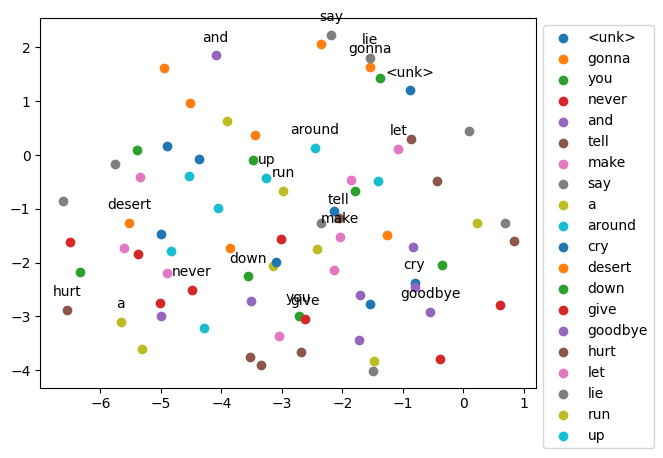

In [37]:
X = model_2.embeddings.weight.cpu().detach().numpy()
tsne = TSNE(n_components=2, random_state=42)
X_2d = tsne.fit_transform(X)
labels = []
for j in range(len(X_2d)):
    if j < 20:
        plt.scatter(X_2d[j, 0], X_2d[j, 1], label=index_to_token[j])
        labels.append(index_to_token[j])
        plt.annotate(index_to_token[j], (X_2d[j, 0], X_2d[j, 1]), textcoords='offset points', xytext=(0, 10), ha='center')
    else:
        plt.scatter(X_2d[j, 0], X_2d[j, 1])
plt.legend(labels, loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

In [38]:
import numpy as np
print(np.__version__)

1.26.4


Repeat the process for a context of four.


In [39]:
CONTEXT_SIZE = 4
model_4 = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)
optimizer = optim.SGD(model_4.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, 1.0, gamma=0.1)
my_loss = train(dataloader, model_4, song)
save_path = '4gram.pth'
torch.save(model_4.state_dict(), save_path)
my_loss_list.append(my_loss)

  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:00<00:00, 161.19it/s]

Generated Song:


You know the rules and so do I guy dont goodbye give cry guy understand on on guy understand thinking hearts goodbye going understand say thinking say from say understand if hearts thinking guy thinking on guy on thinking thinking going say say cry say a understand lie going thinking cry a no on going thinking say a on lie going thinking say hurt lie on going thinking say a goodbye inside on on going thinking cry say say lie going thinking cry on lie going thinking thinking thinking understand other guy on on hurt lie on goodbye what guy understand goodbye what thinking thinking how say cry


The code provided below shows word embeddings from the created model, reduces their dimensionality to 2d using t-SNE, and then plots them as a scatter plot. Additionally, it annotates the first 20 points in the visualization with their corresponding words. This is used to visualize how similar words cluster together in a lower-dimensional space, revealing the structure of the word embeddings. Embeddings allow the model to represent words in a continuous vector space, capturing semantic relationships and similarities between words.


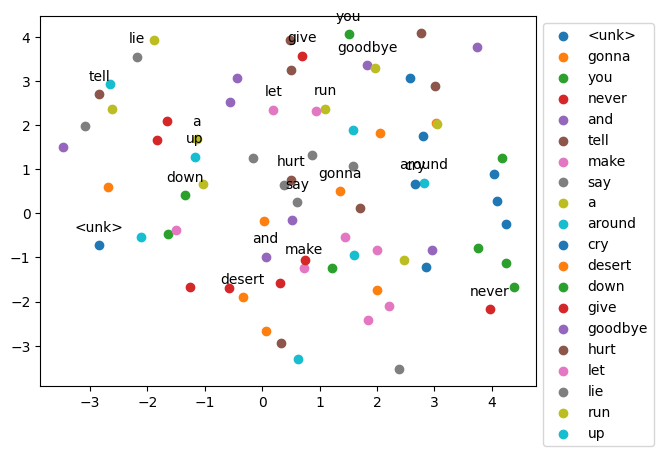

In [40]:
X = model_4.embeddings.weight.cpu().detach().numpy()
tsne = TSNE(n_components=2, random_state=42)
X_2d = tsne.fit_transform(X)
labels = []
for j in range(len(X_2d)):
    if j < 20:
        plt.scatter(X_2d[j, 0], X_2d[j, 1], label=index_to_token[j])
        labels.append(index_to_token[j])
        plt.annotate(index_to_token[j], (X_2d[j, 0], X_2d[j, 1]), textcoords='offset points', xytext=(0, 10), ha='center')
    else:
        plt.scatter(X_2d[j, 0], X_2d[j, 1])
plt.legend(labels, loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

Finally, for a context of eight.


In [41]:
CONTEXT_SIZE = 8
model_8 = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)
optimizer = optim.SGD(model_8.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, 1.0, gamma=0.1)
my_loss = train(dataloader, model_8, song)
save_path = '8gram.pth'
torch.save(model_8.state_dict(), save_path)
my_loss_list.append(my_loss)

  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:00<00:00, 156.08it/s]

Generated Song:


Never gonna tell a lie and hurt you aching the aching hearts know aching know never the down blind know hearts shy blind aching a commitments down know ask feeling know the down this strangers this run blind whats gotta down we <unk> guy never hearts know know never down blind we the the weve play see never how hearts <unk> blind never never make down going it hurt never the hearts never down down going hurt never if hearts hurt know do never never down know ask thinking the hearts aching the aching the weve aching see know you down the if down the get you see


The code provided below shows word embeddings from the created model, reduces their dimensionality to 2D using t-SNE, and then plots them as a scatter plot. Additionally, it annotates the first 20 points in the visualization with their corresponding words. This is used to visualize how similar words cluster together in a lower-dimensional space, revealing the structure of the word embeddings. Embeddings allow the model to represent words in a continuous vector space, capturing semantic relationships and similarities between words.


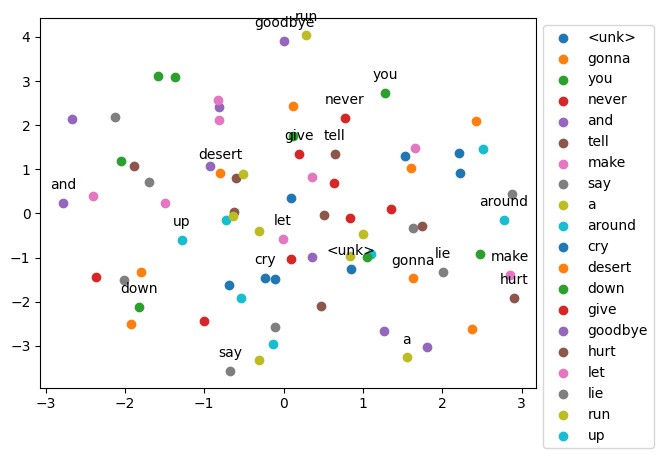

In [42]:
X = model_8.embeddings.weight.cpu().detach().numpy()
tsne = TSNE(n_components=2, random_state=42)
X_2d = tsne.fit_transform(X)
labels = []
for j in range(len(X_2d)):
    if j < 20:
        plt.scatter(X_2d[j, 0], X_2d[j, 1], label=index_to_token[j])
        labels.append(index_to_token[j])
        plt.annotate(index_to_token[j], (X_2d[j, 0], X_2d[j, 1]), textcoords='offset points', xytext=(0, 10), ha='center')
    else:
        plt.scatter(X_2d[j, 0], X_2d[j, 1])
plt.legend(labels, loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

When considering the plotted loss for each model, a discernible trend emerges: an increase in context size correlates with a reduction in loss. While this specific approach lacks the inclusion of model validation or the utilization of conventional NLP evaluation metrics, the visual evidence substantiates its superior performance. 


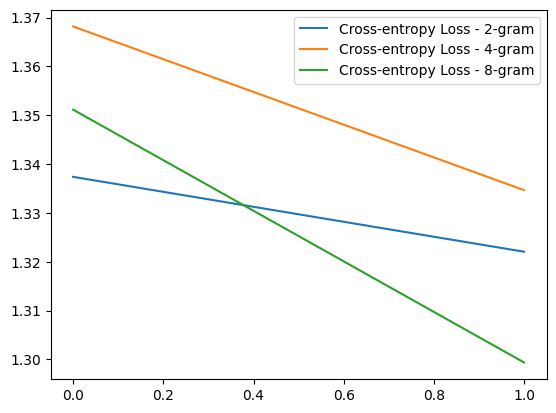

In [43]:
for my_loss, model_name in zip(my_loss_list, ['2-gram', '4-gram', '8-gram']):
    plt.plot(my_loss, label='Cross-entropy Loss - {}'.format(model_name))
    plt.legend()

## Perplexity
Perplexity is a measurement used to evaluate the effectiveness of language models or probability models. It provides an indication of how well a model predicts a sample of data or the likelihood of an unseen event. Perplexity is commonly used in natural language processing tasks, such as machine translation, speech recognition, and language generation.

Perplexity is derived from the concept of cross-entropy loss, which measures the dissimilarity between predicted probabilities and actual probabilities. 

$$\text{Cross-Entropy Loss} = -\sum_{i=1}^{N} y_i \ln(p_i)$$
The cross-entropy loss is calculated by taking the negative sum of the products of the true labels $y_i$ and the logarithm of the predicted probabilities $p_i$ over $N$ classes.

Taking the exponential of the mean cross-entropy loss gives us the perplexity value.

$$\text{Perplexity} = e^{\frac{1}{N} \text{Cross-Entropy Loss}}$$


A lower perplexity value indicates that the model is more confident and accurate in predicting the data. Conversely, a higher perplexity suggests that the model is less certain and less accurate in its predictions.

Perplexity can be seen as an estimate of the average number of choices the model has for the next word or event in a sequence. A lower perplexity means that the model is more certain about the next word, while a higher perplexity means that there are more possible choices.


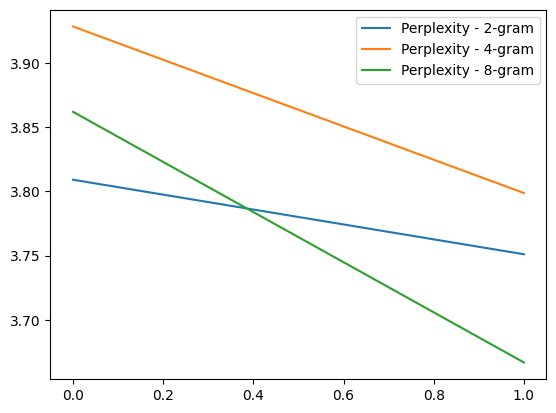

In [44]:
for my_loss, model_name in zip(my_loss_list, ['2-gram', '4-gram', '8-gram']):
    perplexity = np.exp(my_loss)
    plt.plot(perplexity, label='Perplexity - {}'.format(model_name))
    plt.legend()

# Exercises


### Exercise 1 - Source a collection of nursery rhymes and compile them into a single text variable.


In [45]:
nursery_rhymes = "\nLittle Miss Muffet\nSat on a tuffet,\nEating her curds and whey;\nAlong came a spider\nWho sat down beside her\nAnd frightened Miss Muffet away.\n\nTwinkle, twinkle, little star,\nHow I wonder what you are!\nUp above the world so high,\nLike a diamond in the sky.\n\nBaa, baa, black sheep,\nHave you any wool?\nYes sir, yes sir,\nThree bags full.\n\nJack and Jill went up the hill\nTo fetch a pail of water.\nJack fell down and broke his crown,\nAnd Jill came tumbling after.\n\nHickory dickory dock,\nThe mouse ran up the clock.\nThe clock struck one,\nThe mouse ran down,\nHickory dickory dock.\n\nHumpty Dumpty sat on a wall,\nHumpty Dumpty had a great fall.\nAll the king's horses and all the king's men\nCouldn't put Humpty together again.\n\nMary had a little lamb,\nIts fleece was white as snow;\nAnd everywhere that Mary went,\nThe lamb was sure to go.\n\nOld MacDonald had a farm,\nE-I-E-I-O,\nAnd on his farm he had a cow,\nE-I-E-I-O.\n\nItsy Bitsy Spider climbed up the waterspout.\nDown came the rain and washed the spider out.\nOut came the sun and dried up all the rain,\nAnd the Itsy Bitsy Spider climbed up the spout again.\n\nThe wheels on the bus go round and round,\nRound and round,\nRound and round.\nThe wheels on the bus go round and round,\nAll through the town.\n\n"

<details>
    <summary>Click here for Solution</summary>

```python
nursery_rhymes = """
Little Miss Muffet
Sat on a tuffet,
Eating her curds and whey;
Along came a spider
Who sat down beside her
And frightened Miss Muffet away.

Twinkle, twinkle, little star,
How I wonder what you are!
Up above the world so high,
Like a diamond in the sky.

Baa, baa, black sheep,
Have you any wool?
Yes sir, yes sir,
Three bags full.

Jack and Jill went up the hill
To fetch a pail of water.
Jack fell down and broke his crown,
And Jill came tumbling after.

Hickory dickory dock,
The mouse ran up the clock.
The clock struck one,
The mouse ran down,
Hickory dickory dock.

Humpty Dumpty sat on a wall,
Humpty Dumpty had a great fall.
All the king's horses and all the king's men
Couldn't put Humpty together again.

Mary had a little lamb,
Its fleece was white as snow;
And everywhere that Mary went,
The lamb was sure to go.

Old MacDonald had a farm,
E-I-E-I-O,
And on his farm he had a cow,
E-I-E-I-O.

Itsy Bitsy Spider climbed up the waterspout.
Down came the rain and washed the spider out.
Out came the sun and dried up all the rain,
And the Itsy Bitsy Spider climbed up the spout again.

The wheels on the bus go round and round,
Round and round,
Round and round.
The wheels on the bus go round and round,
All through the town.

"""
```

</details>


### Exercise 2 - Preprocess the text data to tokenize and create n-grams.


In [46]:
N = 2
tokens = preprocess(nursery_rhymes)
ngrams = genngrams(tokens)
context, target = ngrams[0]

<details>
    <summary>Click here for Solution</summary>

```python
# Define the value of N for N-grams (context size)
N = 2  

# Preprocess the text (e.g., nursery rhymes) to tokenize and clean it
tokens = preprocess(nursery_rhymes)  # Use the preprocess function to tokenize the text

# Generate N-grams using the `genngrams` function
ngrams = genngrams(tokens)  

# Extract the first context-target pair from the list of N-grams
context, target = ngrams[0]  
```

</details>


### Exercise 3 - Convert Context Words into Embeddings and Pass Them Through a Linear Layer


In [47]:
vocab = tokenizetext(nursery_rhymes)
embedding_dim = 20
linear = nn.Linear(embedding_dim * CONTEXT_SIZE, 128)
embeddings = genembedding(vocab)
my_embeddings = embeddings(torch.tensor(vocab(context)))
my_embeddings = my_embeddings.reshape(1, -1)
output = linear(my_embeddings)
print('Output shape:', output.shape)

Output shape: torch.Size([1, 128])


<details>
    <summary>Click here for Solution</summary>

```python

# Tokenize text and create vocabulary
vocab = tokenizetext(nursery_rhymes)  


# Define embedding dimensions and create layers
embedding_dim = 20  # Each word will be represented as a 20-dimensional vector
linear = nn.Linear(embedding_dim * CONTEXT_SIZE, 128)  


# Generate embeddings using the custom embedding function
embeddings = genembedding(vocab)  


# Convert context words into embeddings
my_embeddings = embeddings(torch.tensor(vocab(context)))  


# Reshape embeddings to match the input shape required by the linear layer
my_embeddings = my_embeddings.reshape(1, -1)  


# Pass embeddings through the linear layer
output = linear(my_embeddings)  


# Print output shape for verification
print("Output shape:", output.shape)  



```

</details>


### Exercise 4 -  Implement Batch Processing with Padding for Language Modeling.


In [48]:
CONTEXT_SIZE = 3
BATCH_SIZE = 10
EMBEDDING_DIM = 10
Padding = BATCH_SIZE - len(tokens) % BATCH_SIZE
tokens_pad = tokens + tokens[0:Padding]
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dataloader = DataLoader(tokens_pad, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
print(f'Total tokens (after padding): {len(tokens_pad)}')

Total tokens (after padding): 240


<details>
    <summary>Click here for Solution</summary>

```python
# Define constants for training
CONTEXT_SIZE = 3  # The number of words in the context window
BATCH_SIZE = 10   # The number of samples per batch
EMBEDDING_DIM = 10  # The dimension of the word embeddings

# Compute padding to ensure the number of tokens is evenly divisible by the batch size
Padding = BATCH_SIZE - len(tokens) % BATCH_SIZE  


tokens_pad = tokens + tokens[0:Padding]  


# Define device (CPU/GPU) for computation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  


# Create DataLoader for batch processing
dataloader = DataLoader(
    tokens_pad, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch
)  


# Print length of total tokens after padding
print(f"Total tokens (after padding): {len(tokens_pad)}")


```

</details>


### Exercise 5 - Train an N-gram language model using the provided code structure.


In [49]:
CONTEXT_SIZE = 2
criterion = torch.nn.CrossEntropyLoss()
model3 = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)
optimizer = optim.SGD(model3.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)
loss_history = train(dataloader, model3, nursery_rhymes)
print(f'Training started with {len(vocab)} words in vocabulary.')
print(f'Optimizer: {optimizer}')
print(f'Learning rate scheduler: {scheduler}')

  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:00<00:00, 157.80it/s]

Generated Song:


 dock are climbed away e-i-e-i-o so king dock climbed horses climbed climbed climbed climbed climbed pail baa so up pail climbed sat climbed climbed the away lamb little cow pail climbed dock sheep climbed her town wool wall e-i-e-i-o so along snow dock fall pail dock pail so climbed humpty climbed climbed climbed sheep on a climbed one climbed climbed climbed spider dock climbed dock climbed muffet climbed pail little dock climbed climbed town e-i-e-i-o again a dock round lamb climbed muffet dock along climbed muffet climbed his wonder sheep town dock dock along king pail little pail climbed pail
Training started with 127 words in vocabulary.
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    initial_lr: 0.01
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)
Learning rate scheduler: <torch.optim.lr_scheduler.StepLR object at 0x12daa6310>


<details>
    <summary>Click here for Solution</summary>

```python
# Define context size for N-gram modeling
CONTEXT_SIZE = 2  # Number of previous words used as context for predicting the next word

# Define the loss function
criterion = torch.nn.CrossEntropyLoss()  

# Initialize the N-gram language model
model3 = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE).to(device)  


# Define the optimizer (Stochastic Gradient Descent)
optimizer = optim.SGD(model3.parameters(), lr=0.01)  

# Implement Learning Rate Scheduling
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)  

# Train the model and track loss history
loss_history = train(dataloader, model3, nursery_rhymes)  


# Output expected behavior
print(f"Training started with {len(vocab)} words in vocabulary.")
print(f"Optimizer: {optimizer}")
print(f"Learning rate scheduler: {scheduler}")
```

</details>


### Exercise 6 - After training, use the model to generate a new nursery rhyme and then print it.


In [50]:
selected_line = pickrandomline(nursery_rhymes)
generated_rhyme = write_song(model3, selected_line)
print(generated_rhyme)

Yes sir, yes sir, dock a climbed away e-i-e-i-o so king dock climbed horses climbed climbed climbed a climbed pail baa so up pail climbed sat climbed climbed the away lamb little cow pail climbed dock sheep climbed her town wool wall e-i-e-i-o so along snow dock fall pail dock pail so climbed humpty climbed climbed climbed sheep on a climbed one climbed climbed climbed spider dock climbed dock climbed muffet climbed pail little dock climbed baa pail e-i-e-i-o again a dock round lamb climbed muffet dock along climbed muffet climbed his wonder sheep town dock dock along king pail little pail climbed pail


<details>
    <summary>Click here for Solution</summary>

```python
# Select a random line from the nursery rhymes dataset
selected_line = pickrandomline(nursery_rhymes)  


# Generate a new rhyme using the trained language model
generated_rhyme = write_song(model3, selected_line)  


# Print the generated rhyme
print(generated_rhyme) 

```

</details>


---


# Congratulations! You have completed the lab


## Authors


[Joseph Santarcangelo](https://www.linkedin.com/in/joseph-s-50398b136/) has a Ph.D. in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


### Contributor

[Roodra Kanwar](https://www.linkedin.com/in/roodrakanwar/) is completing his MS in CS specializing in big data from Simon Fraser University. He has previous experience working with machine learning and as a data engineer.


```{## Change log}


```{|Date (YYYY-MM-DD)|Version|Changed By|Change Description||-|-|-|-||2023-09-01|0.1|Joseph|Created Lab Template & Guided Project||2023-09-03|0.1|Joseph|Updated Guided Project|}


© Copyright IBM Corporation. All rights reserved.
